Marcus Khaleeli 

2381557

04/21/2026

# Homework 3: End-to-End Machine Learning Project using Scikit-Learn

- Objective:
    In this assignment you will implement a complete machine learning workflow using Scikit
Learn. You will explore a dataset, prepare the data, train several machine learning models, 
evaluate their performance, and analyze the results. 

- Goal of Assignment:
    The goal is to understand the entire machine learning pipeline, including data exploration, 
training/testing splits, model comparison, ensemble learning, dimensionality reduction, and 
hyperparameter tuning.

- Dataset: Iris Dataset
    This dataset contains measurements for iris flowers belonging to three different species
    
    Target Classes:
    * Iris Setosa
    * Iris Versicolor
    * Iris Virginica

    Features:
    * Sepal length
    * Sepal width
    * Petal length
    * Petal width

- Model Goal: To predict the species of an iris flower based on these measurements (dataset contains 150 samples)

+ Answers to Questions are Included in this notebook at the end of each Part


In [1298]:
#Standard Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#Iris Dataset
from sklearn.datasets import load_iris
iris = load_iris()

# Part 1: Data Exploration
Tasks:
1. Convert the dataset into a DataFrame. 
2. Print the following information: 
    - number of samples 
    - number of features 
    - names of the features 
    - number of classes 
3. Plot histograms for all four features. 
4. Create at least one scatter plot of two features, colored by the class label.    

In [1299]:
# Part 1 - Task 1
#Creating a dataframe "df" from the iris dataset
df = pd.DataFrame(data = iris.data, columns = iris.feature_names) 
#print("Before adding target or result column: \n: ", df, "\n")

#Initially used df['iris_type'] and df['name_of_iris']
'''
#Create a new column for representing the produced classification for each row of data
#df['iris_type'] = iris.target #iris.target is the array of numeric labels for each species (0 -> Iris setosa, 1 -> Iris versicolor, 2 -> Iris virginica)

#applies a lambda expression (nameless expression) which takes each x value from the target column anda assigns the actual string names for each flower type
#df['name_of_iris'] = df['iris_type'].apply(lambda x: iris.target_names[x]) #iris.target_names contains the string labels ('setosa', 'versicolor', 'virginica')

This created 2 columns of a numeric value along with the type name as a string value 
'''

#Since we already have numerical labels applied, and we only need the names of the iris, we can produce one column using pd.Categorical.from_codes()
'''
pd.Categorical() allows creating categories by order and ease of conversion between integer and string assignment 
.from_codes converts a column into string representation, as -1 is filled in for NaN data
Only produces 1 column of the type names compared to both the numeric representation and string name together as 2 seperate columns
'''
df["name_of_iris"] = pd.Categorical.from_codes(iris.target, iris.target_names)

#Converts dataframe into a tuple of 2 elements; (features, labels) from just (features)
print("After adding result column with string names instead of numeric values: \n" , df)

After adding result column with string names instead of numeric values: 
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9             

In [1300]:
# Part 1 - Task 2
'''
Displaying the number of samples, 
number of features, 
names of features, 
and the number of classes
'''

#Number of Samples
num_of_samples = df.shape[0] #Displays number of rows : 0, which is the number of samples counted 
print("Number of Samples: ", num_of_samples) 

#Number of Features

num_of_feat = df.drop(columns=['name_of_iris']).shape[1] #Displays number of columns : 1, which is the number of features counted, except for the resulting iris name
print("Number of Features: ", num_of_feat)

#Shape is a tuple of dimensions from dataframe, so indexing 0 & 1 selects from df(features, labels)

#Name of Features
feature_names = df.columns.drop('name_of_iris').tolist() #Gets column names into a list format, except for the resulting iris name
print("Feature Names: ", feature_names)

#Number of Classes
num_of_classes = df['name_of_iris'].nunique()
unique_class = df['name_of_iris'].unique().astype(str).tolist() #Gets unique class names, converted into string types, as a list of strings
print("Number of Classes: ", num_of_classes, unique_class)


Number of Samples:  150
Number of Features:  4
Feature Names:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Number of Classes:  3 ['setosa', 'versicolor', 'virginica']


Number of Samples for Sepal length:  150


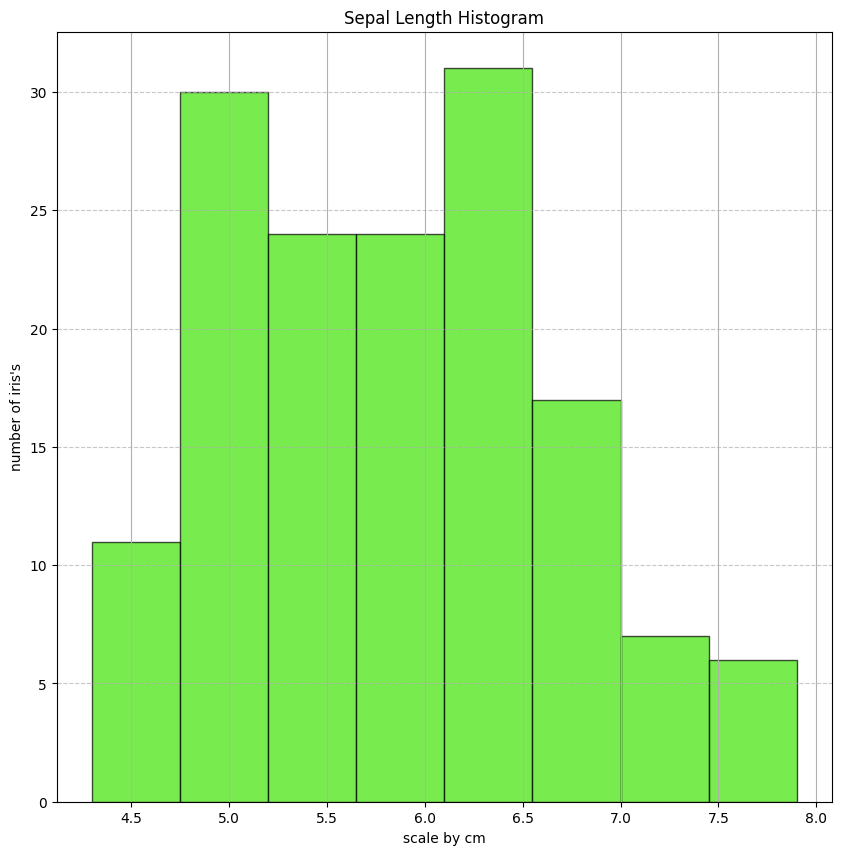

Number of Samples for Sepal width:  150


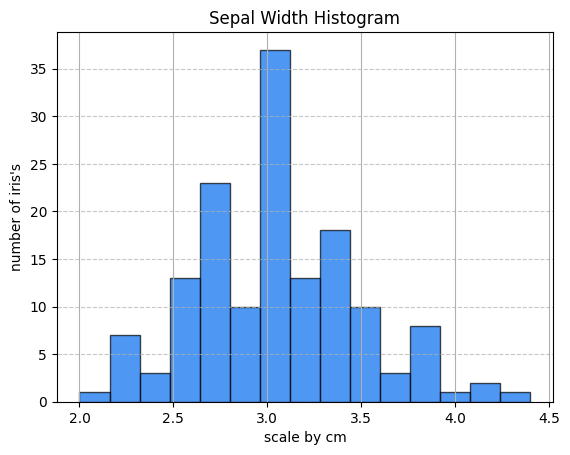

Number of Samples for Petal length:  150


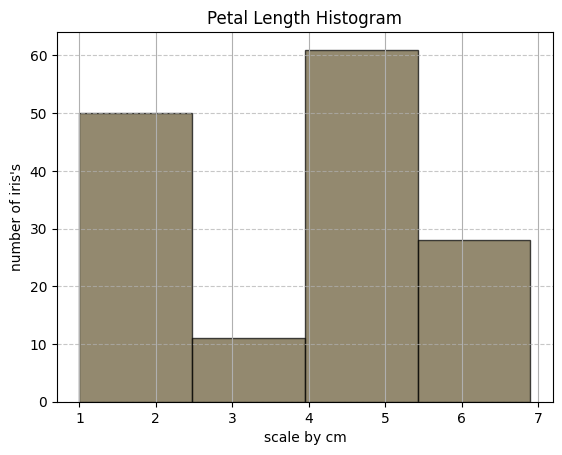

Number of Samples for Petal width:  150


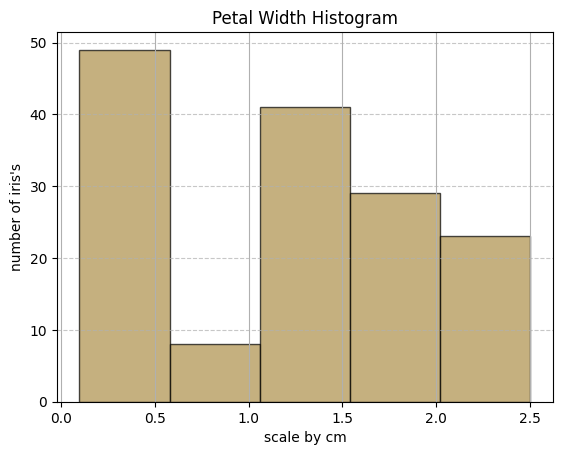

In [1301]:
#Part 1 - Task 3
#Plotting histograms for feature types; each feature has its own histogram

#Histogram for Sepal Length (cm)
#Figure Size
plt.figure(figsize = (10,10))


sepal_len_df = df['sepal length (cm)']
sepal_wid_df = df['sepal width (cm)']
petal_len_df = df['petal length (cm)']
petal_wid_df = df['petal width (cm)']

#Calculating # of bins for the histogram (Q1, Q3, IQR)
def calc_num_bins(data):
    #Interquartile Range (iqr)
    q3, q1 = np.percentile(data, [75, 25])
    iqr = q3 - q1

    #Bin width
    n = data.shape[0]
    bin_width = 2 * iqr / (n ** (1/3))

    #Number of Bins
    num_bins = int(np.ceil((data.max() - data.min())) / bin_width)
    return num_bins

num_of_bins_1 = calc_num_bins(sepal_len_df)
num_of_bins_2 = calc_num_bins(sepal_wid_df)
num_of_bins_3 = calc_num_bins(petal_len_df)
num_of_bins_4 = calc_num_bins(petal_wid_df)

#Histogram
def histo(data, num_of_bins):
    #color randomizer
    rand_color = (np.random.random(), np.random.random(), np.random.random())

    #graphing
    data.hist(bins=num_of_bins, color=rand_color, edgecolor='black', alpha = 0.7)
    plt.xlabel("scale by cm")
    plt.ylabel("number of iris's")
    #Added gridlines
    plt.grid(axis='y', linestyle='--', alpha = 0.7)
    plt.show()
    
#Plot Histograms for each feature and the number of samples
print("Number of Samples for Sepal length: ", sepal_len_df.shape[0])
plt.title("Sepal Length Histogram")
histo(sepal_len_df, num_of_bins_1)

print("Number of Samples for Sepal width: ", sepal_wid_df.shape[0])
plt.title("Sepal Width Histogram")
histo(sepal_wid_df, num_of_bins_2)

print("Number of Samples for Petal length: ", petal_len_df.shape[0])
plt.title("Petal Length Histogram")
histo(petal_len_df, num_of_bins_3)

print("Number of Samples for Petal width: ", petal_wid_df.shape[0])
plt.title("Petal Width Histogram")
histo(petal_wid_df, num_of_bins_4)

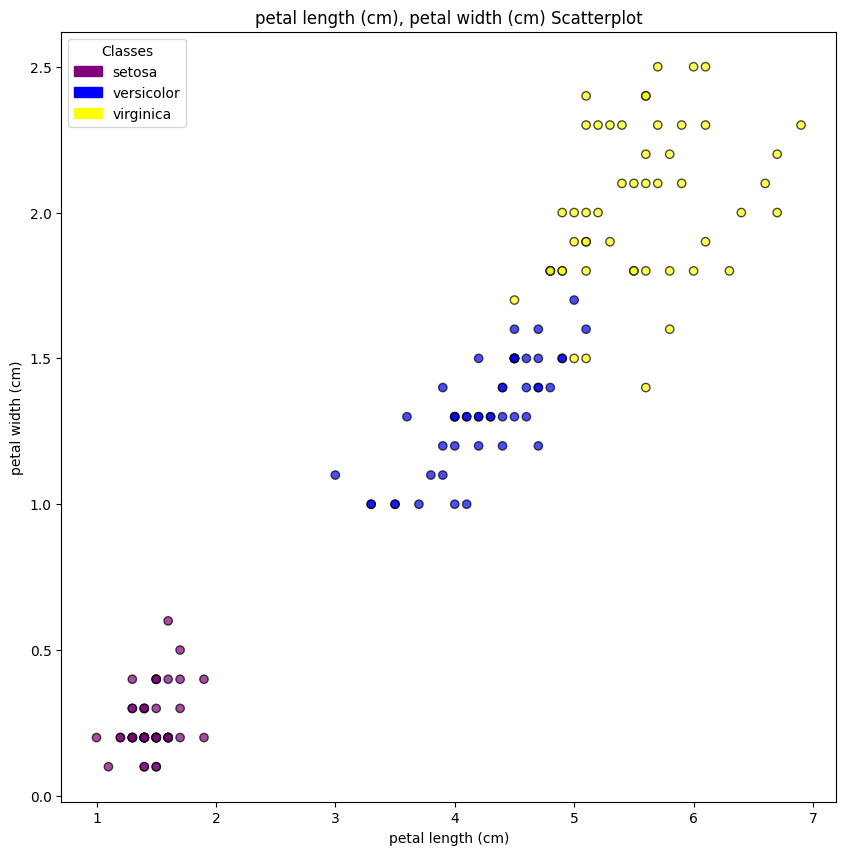

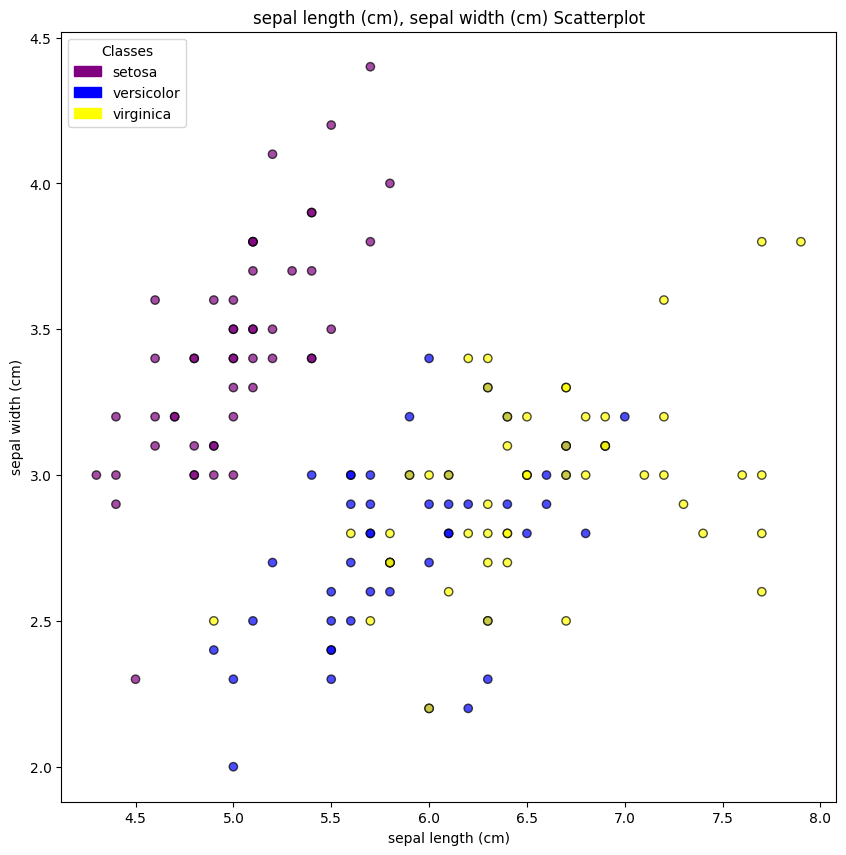

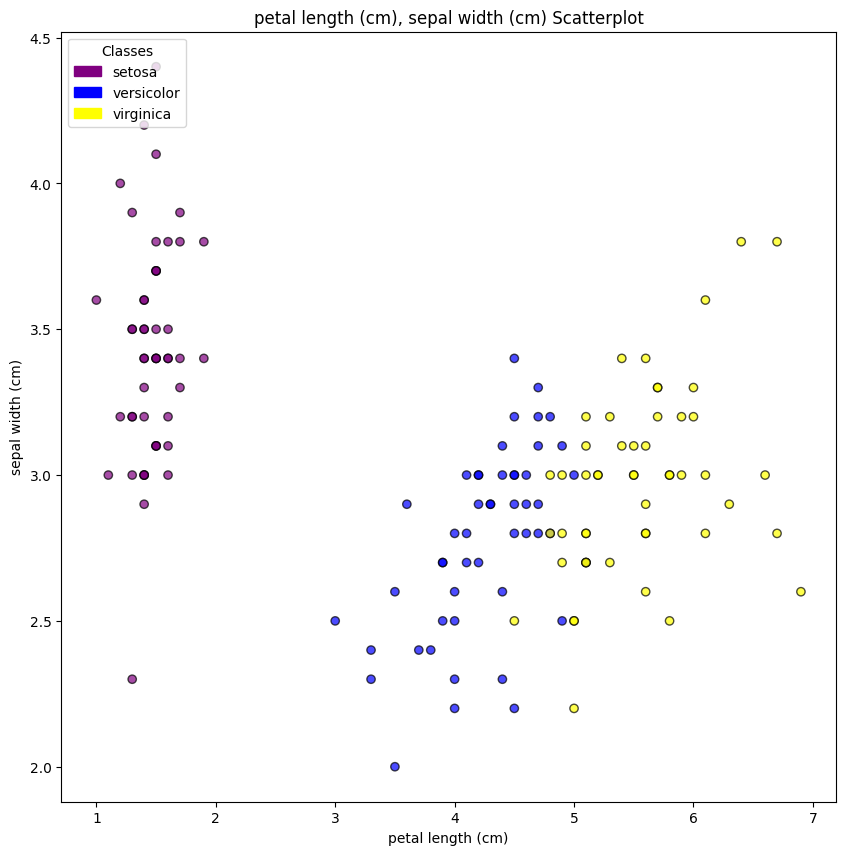

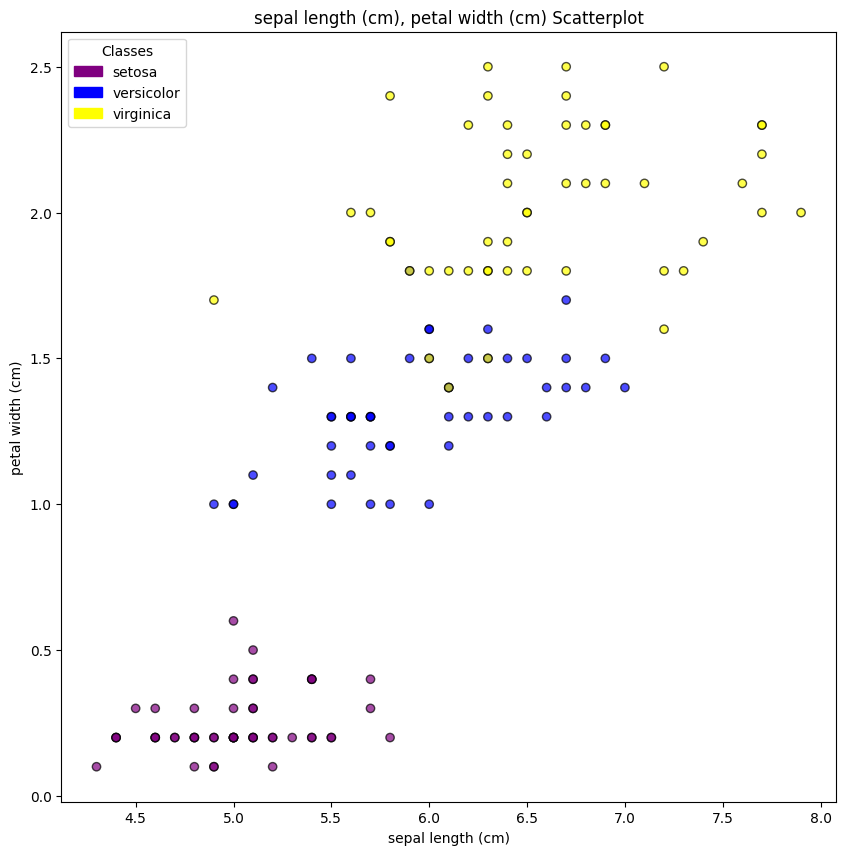

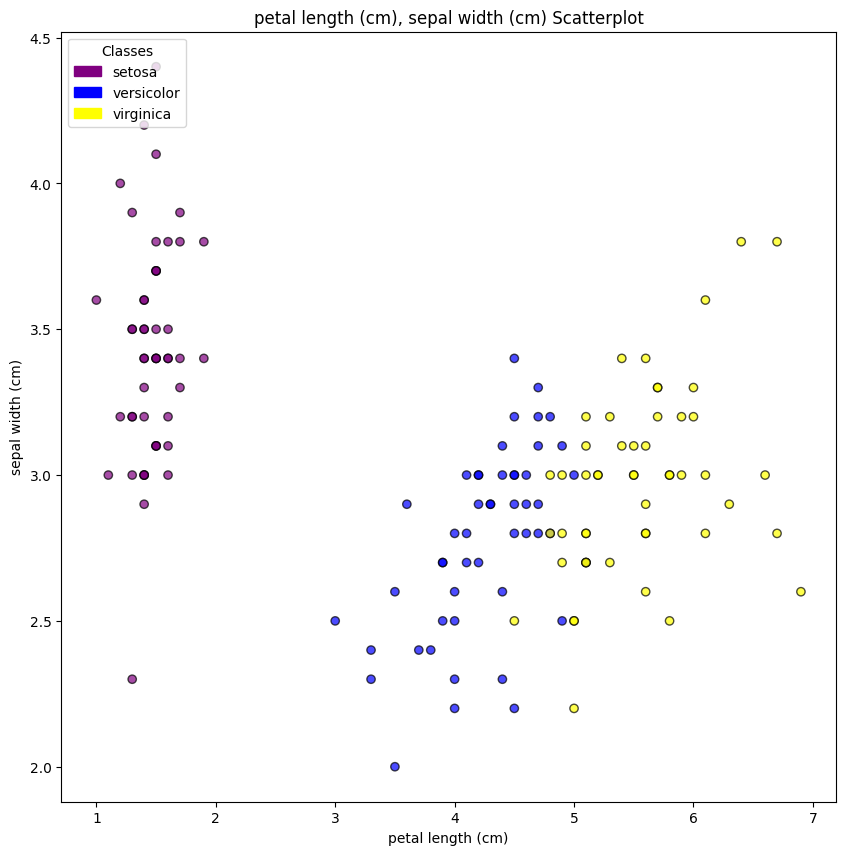

name_of_iris
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [1302]:
#Part 1 - Task 4
# Create at least one scatter plot of two seperate features, colored by the class label
import matplotlib.patches as mpatch

def two_feat_scatter(feature_x, feature_y):
    
    data = df #Data of iris

    #Unique Class Types
    unique_class = df['name_of_iris'].unique().astype(str).tolist() #Gets unique class names, converted into string types, as a list of strings

    classa, classb, classc = unique_class #Variables for each class

    #Color Association
    color_dict = {classa:'purple', classb:'blue', classc:'yellow'}

    #Colors of datapoints
    point_colors = df['name_of_iris'].map(color_dict) #Colors mapped per row

    #Graph Figure & Labels
    plt.figure(figsize=(10,10))
    
    plt.scatter(data[feature_x], data[feature_y], c=point_colors, edgecolor = 'black', alpha = 0.7)
    plt.xlabel(f"{feature_x}")
    plt.ylabel(f"{feature_y}")
    plt.title(f"{feature_x}, {feature_y} Scatterplot")

    # Legend patches (automatically gets # of labels needed from defined dictionary & # of classes)
    legend_patches = [
    mpatch.Patch(color=color_dict[c], label=c)
    for c in unique_class
    ]

    plt.legend(handles=legend_patches, loc="upper left", title="Classes")
    plt.show()

two_feat_scatter('petal length (cm)','petal width (cm)')
two_feat_scatter('sepal length (cm)','sepal width (cm)')
two_feat_scatter('petal length (cm)','sepal width (cm)')
two_feat_scatter('sepal length (cm)','petal width (cm)')
two_feat_scatter('petal length (cm)','sepal width (cm)')

# Number of samples belonging to each class:
count = df['name_of_iris'].value_counts()
print(count)




Part 1 Q/A:
1. How many samples belong to each class?
    Ans: 50 of each class type
    - Number of setosa: 50
    - Number of versicolor: 50
    - Number of virginica: 50
2. Which pair of features appears to separate the classes most clearly? 
    Ans: The setosa class as it is more visibly seperated using petal length and petal width (1st scatterplot), compared to both versicolor and virginica.

# Part 2: Train-Test-Split
Tasks:
1. Split 80% training data, 20% testing data

In [1303]:
# Part 2 - Task 1
#Train Test Split into 80% training data, 20% testing data
from sklearn.model_selection import train_test_split

'''Don't manipulate df to avoid issues with modified original data'''

#Unique Class Types
unique_class = df['name_of_iris'].unique().astype(str).tolist()
classa, classb, classc = unique_class #Variables for each class

#Number Association
class_nums = {classa: 0, classb: 1, classc: 2}
y = df['name_of_iris'].map(class_nums) #Only Classifiers in Numeric Form

#Drop Classification for training data 
X = df.drop(columns = ['name_of_iris']) #Rest of dataset without classifiers

print(X, y)

#Test / Train split for 80/20 relation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=200)






     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  5.1               3.5                1.4               0.2
1                  4.9               3.0                1.4               0.2
2                  4.7               3.2                1.3               0.2
3                  4.6               3.1                1.5               0.2
4                  5.0               3.6                1.4               0.2
..                 ...               ...                ...               ...
145                6.7               3.0                5.2               2.3
146                6.3               2.5                5.0               1.9
147                6.5               3.0                5.2               2.0
148                6.2               3.4                5.4               2.3
149                5.9               3.0                5.1               1.8

[150 rows x 4 columns] 0      0
1      0
2      0
3      0
4   

Part 2 Q/A:
1. Why do we split the dataset into training and testing sets?
    Ans:
    We split the dataset into training and testing sets to evaluate how well the model can classify unforseen data; training the model on data and then asking it to correctly classify unseen data. 


2. What problem occurs if we evaluate a model using the same data that was used to train it?
    Ans:     
    Using only the dataset to train and test our model would be bias, as the model already knows the expected classification. Leading to overfitting on the model to a specific dataset. 
    


# Part 3: Feature Scaling
1. Standardize the dataset so that each feature has mean = 0, std deviation = 1

In [1304]:
#Part 3 - Task 1
'''
# Standardize (Z_score) the dataset so that each feature has:
- mean = 0
- standard deviation = 1

This only modifies defined dataset X, adding upon the previous defined X_train, y_train, X_test, y_tests
'''
from sklearn.preprocessing import StandardScaler

#Selecting only numeric columns
numeric_cols = X.select_dtypes(include=['number']).columns

#Fit and transform numeric columns 
scaler = StandardScaler()

#Fits to df's numeric values 
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print("Standardized Dataframe (mean=0, std = 1): \n", X,"\n")



Standardized Dataframe (mean=0, std = 1): 
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0            -0.900681          1.019004          -1.340227         -1.315444
1            -1.143017         -0.131979          -1.340227         -1.315444
2            -1.385353          0.328414          -1.397064         -1.315444
3            -1.506521          0.098217          -1.283389         -1.315444
4            -1.021849          1.249201          -1.340227         -1.315444
..                 ...               ...                ...               ...
145           1.038005         -0.131979           0.819596          1.448832
146           0.553333         -1.282963           0.705921          0.922303
147           0.795669         -0.131979           0.819596          1.053935
148           0.432165          0.788808           0.933271          1.448832
149           0.068662         -0.131979           0.762758          0.790671

[150 rows x 4 colum

Part 3 Q/A: 
1. Why is feature scaling important for some machine learning algorithms? 
    Ans: Feature Scaling is a preprocessing step which transforms features to a comparable scale to ensure no features are more influential due to their magnitude. Treating all features with fairness. 

2. Which algorithms benefit the most from standardized features? 
    Ans: standarding the features benefits:
     -  Logistic Regression Algorithms: 
        gradient descent (gd), schocastic gradient descent (sgd), support vector machine (svm) 
    
    - Clustering: k-Means, k-Nearest Neighbors (knn)
     
    - Principal Component Analysis (PCA): dependent on relative variance distance between datapoints, which must be preserved for reducing dimensionality.

     These algorithms converge faster and perform better when standardized to have features on a similar scale of values.

Note: Standardization (Z_score) is the process of ensuring all features are on the same scale. 

# Part 4: Train Multiple Models
Train the following classifiers using the training dataset:
1. Logistic Regression
2. Support Vector Machine (SVM)
3. Decision Tree

For Each Model:
1. Train the model using the training data. 
2. Predict the labels of the test data. 
3. Compute the accuracy. 

Then Create a table comparing the accuracy of all three models.

In [1305]:
#Resplitting Test and Training dataset to see difference more clearly 90/10 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90, random_state=13)

In [1306]:
#Part 4 - Task 1
#Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#Logistic Regression Model:
model = LogisticRegression()
model.fit(X_train, y_train)

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Make a Prediction
y_pred = model.predict(X_test)

#Determine Accuracy
log_accuracy = accuracy_score(y_test, y_pred)

#Remapping data from 1 & 0 to actual Personality Result
replace_map = {0: classa, 1: classb, 2: classc}

# Replace numeric representation using list comprehension for class names
log_final_pred = [replace_map.get(x, x) for x in y_pred]
log_final_val = [replace_map.get(x, x) for x in y_test]

print("Prediction: ", log_final_pred)
print("Actual:     ", log_final_val)

print("Accuracy: ", log_accuracy * 100, '%')

log_classify = classification_report(log_final_pred, log_final_val)
print("Classification Report: \n", log_classify)


model:  LogisticRegression 

Prediction:  ['versicolor', 'versicolor', 'setosa', 'virginica', 'virginica', 'setosa', 'virginica', 'versicolor', 'setosa', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'versicolor', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'versicolor', 'vir

In [1307]:
#Part 4 - Task 2
#SVM Model
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

#Resplitting Test and Training dataset to see difference more clearly 90/10 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90, random_state=13)

#SVM Model:
# model = SVC(kernel = 'linear', C = 1.0)
# model.fit(X_train, y_train)

# placeholder 'model' for error checking
model = SVC()

#Model SVM Model using a Pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm_clf', SVC(kernel='poly', degree = 2, coef0 = 0.7, C = 1))
])

pipe.fit(X_train, y_train)

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Make a Prediction
y_pred = pipe.predict(X_test)

#Determine Accuracy
svm_accuracy = accuracy_score(y_test, y_pred)

#Remapping data from 1 & 0 to actual Personality Result
replace_map = {0: classa, 1: classb, 2: classc}

# Replace numeric representation using list comprehension for class names
svm_final_pred = [replace_map.get(x, x) for x in y_pred]
svm_final_val = [replace_map.get(x, x) for x in y_test]

print("Prediction: ", svm_final_pred)
print("Actual:     ", svm_final_val)

print("Accuracy: ", svm_accuracy * 100, '%')

svm_classify = classification_report(svm_final_val, svm_final_pred)
print("Classification Report: \n", svm_classify)


model:  SVC 

Prediction:  ['versicolor', 'versicolor', 'setosa', 'virginica', 'virginica', 'setosa', 'virginica', 'virginica', 'setosa', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'virginica', 'versicol

In [1308]:
#Part 4 - Task 3
#Decision Tree
from sklearn.tree import DecisionTreeClassifier

#Decision Tree Classifier Model:
model = DecisionTreeClassifier(max_depth = 3)
model.fit(X_train, y_train)

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Make a Prediction
y_pred = model.predict(X_test)

#Determine Accuracy
tree_accuracy = accuracy_score(y_test, y_pred)

#Remapping data from 1 & 0 to actual Personality Result
replace_map = {0: classa, 1: classb, 2: classc}

# Replace numeric representation using list comprehension for class names
tree_final_pred = [replace_map.get(x, x) for x in y_pred]
tree_final_val = [replace_map.get(x, x) for x in y_test]

print("Prediction: ", tree_final_pred)
print("Actual:     ", tree_final_val)

print("Accuracy: ", tree_accuracy * 100, '%')

tree_classify = classification_report(tree_final_val, tree_final_pred)
print("Classification Report: \n", tree_classify)

model:  DecisionTreeClassifier 

Prediction:  ['versicolor', 'versicolor', 'setosa', 'virginica', 'virginica', 'setosa', 'virginica', 'virginica', 'setosa', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'vi

In [1309]:
#Table Comparing the accuracy of all 3 models:

#Table Data
table_data = [['Model','Accuracy'],['LogisticRegression', f'{log_accuracy:.4f}'],['SupportVectorMachine',f'{svm_accuracy:.4f}'],['DecisionTreeClassifier', f'{tree_accuracy:.4f}']]

def Built_Table(table_data):
    
    #Determine Column Width
    col_width = [max(len(str(row[i])) for row in table_data) for i in range(len(table_data[0]))]
    
    #display each row with proper spacing
    def print_row(row):
        for i, cell in enumerate(row):
            print(str(cell).ljust(col_width[i]), end="  ")
        print()
    
    #display table
    print_row(table_data[0]) #Header
    print('-' * (sum(col_width) + 2 * len(col_width))) #Seperator

    #Information in Table
    for row in table_data[1:]:
        print_row(row)

Built_Table(table_data)






Model                   Accuracy  
----------------------------------
LogisticRegression      0.8889    
SupportVectorMachine    0.9630    
DecisionTreeClassifier  0.9556    


Part 4: Q/A
1. Which model performed best? 
    Ans: Initially, DecisionTreeClassifier does the best. However once I changed SVM from a 'linear' kernel to a 'poly' kernel, Support Vector Machine performed the best overall. 

2. Which model is easiest to interpret? 
    Ans: The LogisticRegression model is easiest to interpret as we are predicting the probability for a valid result or category with a linear model, in this case we are predicting the probability of which of the 3 types of iris's would a iris be classified. It is the most straight forward solution for trying to identify the distribution of iris's out of the models used in Part 4. 



# Part 5: Random Forest

Tasks:
1. Train a Random Forest classifier using the training data. 
2. Evaluate the model on the test data. 
3. Extract and display the feature importance values.



In [1310]:
#Part 5 - Task 1
#Training a Random Forest Classifier using the Training Data
from sklearn.ensemble import RandomForestClassifier

#Random Forest Classifier:
model = RandomForestClassifier(n_estimators= 100, oob_score=True, max_depth = 3) #oob_score provides generalized error, n_estimators is the number of n trees used before averaging 

#Training the Model:
model.fit(X_train, y_train)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [1311]:
#Part 5 - Task 2
#Evaluating the Model on Test Data

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Make a Prediction
y_pred = model.predict(X_test)

#Determine Accuracy
rand_accuracy = accuracy_score(y_test, y_pred)

#Remapping data from 1 & 0 to actual Personality Result
replace_map = {0: classa, 1: classb, 2: classc}

# Replace numeric representation using list comprehension for class names
rand_final_pred = [replace_map.get(x, x) for x in y_pred]
rand_final_val = [replace_map.get(x, x) for x in y_test]

print("Prediction: ", rand_final_pred)
print("Actual:     ", rand_final_val)

print("Accuracy: ", rand_accuracy * 100, '%')

rand_classify = classification_report(rand_final_val, rand_final_pred)
print("Classification Report: \n", rand_classify)

print("Model OOB Score: ", model.oob_score_) #accuracy on model of unseen data


model:  RandomForestClassifier 

Prediction:  ['versicolor', 'versicolor', 'setosa', 'virginica', 'virginica', 'setosa', 'virginica', 'virginica', 'setosa', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'v

Classification Report: 
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        45
  versicolor       0.89      0.95      0.92        44
   virginica       0.95      0.89      0.92        46

    accuracy                           0.95       135
   macro avg       0.95      0.95      0.95       135
weighted avg       0.95      0.95      0.95       135

Model OOB Score:  0.8666666666666667


In [1312]:
#Part 5 - Task 3
#Getting Feature Importance Values

#Relevance of each feature towards getting the classification of iris
importances = model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print('\n Feature Importance: \n')
print(importance_df)





 Feature Importance: 

             Feature  Importance
3   petal width (cm)    0.392946
2  petal length (cm)    0.389061
0  sepal length (cm)    0.128027
1   sepal width (cm)    0.089966


Part 5: Q/A
1. Which features are most important for classification? 
Ans: Based on the 4 features, petal width is the most important feature for classifying the type of iris. The next most important feature would be petal length. 

2. Does the Random Forest perform better than a single Decision Tree? 
Ans: In this scenario, based on the accuracy of both models, the DecisionTreeClassifier has a higher accuracy.

- RandomForest gives greater diversity but has the tradeoff of higher bias for lower variance. This can cause the RandomForest to perform worse than the BinaryTree as it is less bias and more averaged results from multiple trees.
- RandomForest makes it easy for measuring the importance of features.

3. Why might ensemble methods improve prediction accuracy? 
Ans: Ensemble methods combine models and their predictions together for form a better predictor. By using emsemble methods, we can improve accuracy slightly by making a combined classification from different models. 


# Part 6: Dimensionality Reduction using PCA

Tasks:
1. Apply Principal Component Analysis (PCA). 
2. Reduce the dataset to two principal components. 
3. Plot the data in the new 2-dimensional space. 
4. Train an SVM classifier using the PCA-transformed data.



In [1313]:
#Part 6 - Task 1 & 2:
from sklearn.decomposition import PCA

#PArt 6 - Tasl 1:
#Principal Component Analysis (PCA):
pca = PCA(n_components = 2) #Reduces Dataset to 2 principcal components

#print(X)

#Part 6 - Task 2:
X_2D = pca.fit_transform(X) #Transforms X into 2 components (2 features)
print('X Modified: \n', X_2D, '\n Shape: ', X_2D.shape)


#Re-Split Model with 2D transform
X_2Dtrain, X_2Dtest, y_2Dtrain, y_2Dtest = train_test_split(X_2D, y, test_size=0.90, random_state=13)

# print('X_2D Train:\n',X_2Dtrain,'\n')
# print('y_2D Train:\n',y_2Dtrain)





X Modified: 
 [[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]
 [-2.07563095  1.48917752]
 [-2.44402884  0.0476442 ]
 [-2.23284716  0.22314807]
 [-2.33464048 -1.11532768]
 [-2.18432817 -0.46901356]
 [-2.1663101   1.04369065]
 [-2.32613087  0.13307834]
 [-2.2184509  -0.72867617]
 [-2.6331007  -0.96150673]
 [-2.1987406   1.86005711]
 [-2.26221453  2.68628449]
 [-2.2075877   1.48360936]
 [-2.19034951  0.48883832]
 [-1.898572    1.40501879]
 [-2.34336905  1.12784938]
 [-1.914323    0.40885571]
 [-2.20701284  0.92412143]
 [-2.7743447   0.45834367]
 [-1.81866953  0.08555853]
 [-2.22716331  0.13725446]
 [-1.95184633 -0.62561859]
 [-2.05115137  0.24216355]
 [-2.16857717  0.52714953]
 [-2.13956345  0.31321781]
 [-2.26526149 -0.3377319 ]
 [-2.14012214 -0.50454069]
 [-1.83159477  0.42369507]
 [-2.61494794  1.79357586]
 [-2.44617739  2.15072788]
 [-2.10997488 -0.46020184]
 [-2.2078089  -0.2061074 ]
 [-2.04514621 

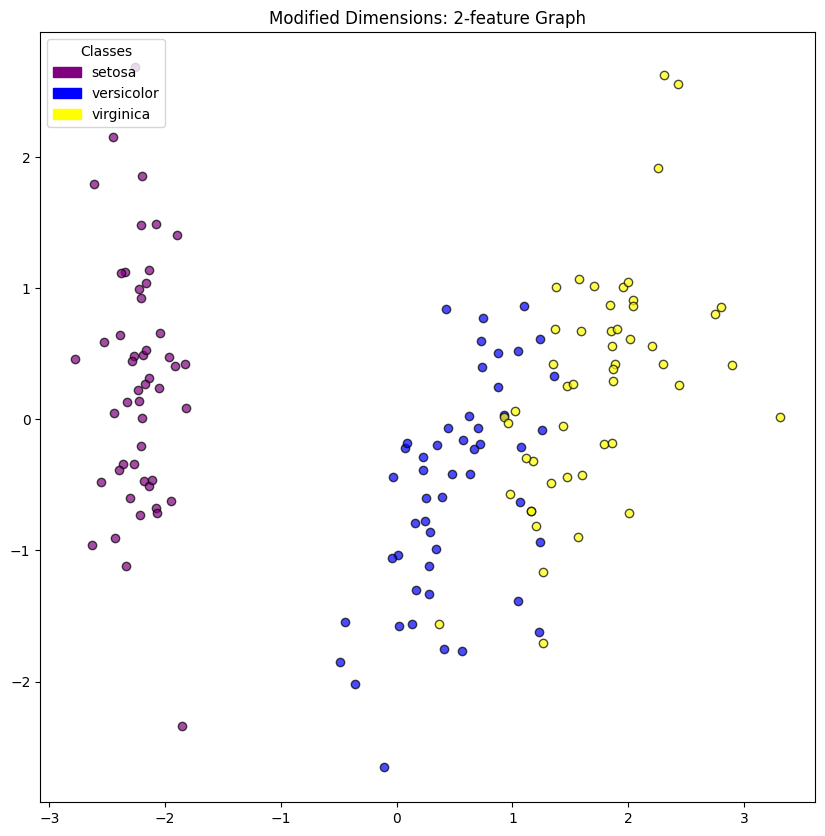

In [1314]:
#Part 6 - Task 3
#Plot data on 2D Space

#Unique Class Types
unique_class = df['name_of_iris'].unique().astype(str).tolist()

classa, classb, classc = unique_class #Variables for each class

#Color Association
color_dict = {classa:'purple', classb:'blue', classc:'yellow'}

#Graph Figure & Labels
plt.figure(figsize=(10,10))

# Legend patches (automatically gets # of labels needed from defined dictionary & # of classes)
legend_patches = [
    mpatch.Patch(color=color_dict[c], label=c)
    for c in unique_class
    
    ]

plt.legend(handles=legend_patches, loc="upper left", title="Classes")
plt.title("Modified Dimensions: 2-feature Graph")

#Generating Graph for each datapoint
for i, target_name in enumerate(iris.target_names):
    class_name = unique_class[i]
    point_color = color_dict[class_name]
    plt.scatter(X_2D[y == i, 0], X_2D[y == i, 1], c=point_color, edgecolors='black', alpha = 0.7, label = class_name)


In [1315]:
#Part 6 - Task 4
#Training SVM classifier using the PCA-transformed data

# placeholder 'model' for error checking
model = SVC()

#Model SVM Model using a Pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm_clf', SVC(kernel='poly', degree = 2, coef0 = 0.7, C = 1))
])

pipe.fit(X_2Dtrain, y_2Dtrain)

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Make a Prediction
y_2Dpred = pipe.predict(X_2Dtest)

#Determine Accuracy
pca_svm_accuracy = accuracy_score(y_2Dtest, y_2Dpred)

#Remapping data from 1 & 0 to actual Personality Result
replace_map = {0: classa, 1: classb, 2: classc}

# Replace numeric representation using list comprehension for class names
svm_final_pred = [replace_map.get(x, x) for x in y_2Dpred]
svm_final_val = [replace_map.get(x, x) for x in y_2Dtest]

print("Prediction: ", svm_final_pred)
print("Actual:     ", svm_final_val)

print("Accuracy: ", pca_svm_accuracy * 100, '%')

svm_classify = classification_report(svm_final_val, svm_final_pred)
print("Classification Report: \n", svm_classify)

#Getting The Variance Ratio
ratios = pca.explained_variance_ratio_
print("Individual Variance Ratios: ", ratios)

#Get Cumulative Sum of Variance Retained from original data
Variance_PC1 = pca.explained_variance_ratio_[0]
Variance_PC2 = pca.explained_variance_ratio_[1]

print("Total Variance: ", Variance_PC1 + Variance_PC2)


model:  SVC 

Prediction:  ['versicolor', 'versicolor', 'setosa', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'versicolor', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'virginica', 'setosa', 'setosa', 'setosa', 'virginica', 'versicolor', 'versicolor', 'virginica', 'virginica', 'versic

Part 6: Q/A
1. How much variance is explained by the first two principal components?
 - Variance Accounts for the measure of how much total variance in the data is captured by the principal components. 

 Ans: The First Principal Component has the most variance of 0.7296, while the 2nd Principal Component has 0.2285. Therefore, the Principal Components represents 73% and 22% of the total variance or info respectively, from the dataset. Together there is a combined 0.9581, or 95% variance captured or retained by the dimensional transformation. 

2. Does dimensionality reduction improve or reduce classification accuracy?
    Ans: Dimensionality reduction reduces the accuracy of the classification for this model. 
    - Dimensionality reduction improves the accuracy when features are closely related. Reducing overfitting by simplifying and organizing data into unrelated principal components or groupings. 
    - Dimensionality reduction reduces accuracy when information is of low variance or a small portion of the data required to determine the accuracy. Discarding information by prioritization of variance, not by class seperation. 

3. Why might PCA sometimes reduce model performance? 
    Ans: The combiantion of features into principal components can ignore lower variance data, as it prioritizes directions of maximum variance, discarding it when related data is combined together into a smaller dimension. PCA could also mix unrelated features together, as each Principal Compoennt is a weighted combination of all original features, causing an  oversimplification of the original data. 


# Part 7: Hyperparameter Tuning

Tasks:
1. Tune the SVM regularization parameter (C). 
2. Train SVM models using several different values of C. 
3. Identify the value that produces the best performance.



In [1316]:
#Part 7 - Task 1
#Tune the Support Vector Machine using Several Different Values of C

best_accuracy = 0
C_value = 0
C_best = None #Empty value

#check valid model being used
print('model: ', type(model).__name__ , '\n')

#Part 7 - Task 2
for i in range(0, 20):
    C_value += 0.05

    pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm_clf', SVC(kernel='poly', degree = 2, coef0 = 0.7, C = C_value))
    ])

    print(f'C_value: {C_value:.2f}')
    pipe.fit(X_train, y_train)

    #Make a Prediction
    y_pred = pipe.predict(X_test)

    #Determine Accuracy
    svm_accuracy = accuracy_score(y_test, y_pred)
    
    #Display Accuracy
    print("Accuracy:", svm_accuracy * 100, '% \n')

    if(svm_accuracy > best_accuracy):
        best_accuracy = svm_accuracy
        C_best = C_value

#Part 7 - Task 3
print(f"Best Accuracy {best_accuracy:%}, Best C_value {C_best:.2f}")






model:  SVC 

C_value: 0.05
Accuracy: 62.96296296296296 % 

C_value: 0.10
Accuracy: 65.92592592592592 % 

C_value: 0.15
Accuracy: 68.14814814814815 % 

C_value: 0.20
Accuracy: 73.33333333333333 % 

C_value: 0.25
Accuracy: 80.74074074074075 % 

C_value: 0.30
Accuracy: 82.96296296296296 % 

C_value: 0.35
Accuracy: 87.4074074074074 % 

C_value: 0.40
Accuracy: 91.85185185185185 % 

C_value: 0.45
Accuracy: 92.5925925925926 % 

C_value: 0.50
Accuracy: 93.33333333333333 % 

C_value: 0.55
Accuracy: 94.81481481481482 % 

C_value: 0.60
Accuracy: 96.29629629629629 % 

C_value: 0.65
Accuracy: 96.29629629629629 % 

C_value: 0.70
Accuracy: 97.03703703703704 % 

C_value: 0.75
Accuracy: 96.29629629629629 % 

C_value: 0.80
Accuracy: 96.29629629629629 % 

C_value: 0.85
Accuracy: 96.29629629629629 % 

C_value: 0.90
Accuracy: 96.29629629629629 % 

C_value: 0.95
Accuracy: 96.29629629629629 % 

C_value: 1.00
Accuracy: 96.29629629629629 % 

Best Accuracy 97.037037%, Best C_value 0.70


Part 7: Q/A
1. Which value of C performed best? 
Ans: 
    C = 0.7 Performed the best. 
 
2. How does changing C affect model flexibility and overfitting? 
Ans:
- Larger C -> Less Flexible -> More Complex Decision Boundary -> Higher Risk to Overfit 
- Smaller C -> More Flexible -> Less Complex Decision Boundary -> Lower Risk to Overfit


# Part 8: Reflection Questions
Answer Briefly:
1. Which model performed best overall? 
Ans: SVM + HyperParameter tuning performed the best at ~97% Accuracy. 

2. What advantages do ensemble models provide compared to single models? 
    Ans: The advantages of utilizing multiple models to determine a combined classification is by leveraging the diversity of each model's ability to reduce the variance, bias of data, and overfitting in order to get a higher accuracy of correctly classifying data. 
- Ensemble Methods: RandomForest, Gradient Boosting, Voting Classifiers, Bagging
- Tradeoff is the added complexity and resources required, as well as longer compute time. 

3. What did you learn from applying PCA to this dataset? 
    Ans: PCA can reduce the amount of features for the potential cost of loosing initial data related values, as it tries to maintain the total variance or information from original features in Principal Components. Allowing a reduction of dimensions to allow graphing in lower dimensions, as well as the additional benefit of avoiding overfitting. 


In [1317]:
#Accuracy Comparison Table for all models
Table_Data = [['Model','Accuracy'],['LogisticRegression', f'{log_accuracy:.4f}'],['SupportVectorMachine',f'{svm_accuracy:.4f}'],['DecisionTreeClassifier', f'{tree_accuracy:.4f}'],['RandomForestClassifier', f'{rand_accuracy:.4f}'],['SVM + PCA', f'{pca_svm_accuracy:.4f}'],['SVM + Hyperparameter', f'{best_accuracy:.4f}']]

Built_Table(Table_Data)

Model                   Accuracy  
----------------------------------
LogisticRegression      0.8889    
SupportVectorMachine    0.9630    
DecisionTreeClassifier  0.9556    
RandomForestClassifier  0.9481    
SVM + PCA               0.8815    
SVM + Hyperparameter    0.9704    
